In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from sklearn.preprocessing import StandardScaler,OneHotEncoder,PolynomialFeatures
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error,r2_score,mean_absolute_error
import warnings
warnings.filterwarnings("ignore")

### 1. Environment Setup & Data Ingestion
* **Libraries Imported**: Loaded core data science libraries including Pandas, NumPy, Scikit-Learn (for linear models, preprocessing pipelines, imputation, and grid search), and Matplotlib/Seaborn for exploratory checks.
* **Dataset Loaded**: Pulled the California Housing dataset directly from the source repository to evaluate continuous regression performance (predicting median house values based on spatial and demographic features).

In [2]:
df=pd.read_csv("https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv")
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


### 1a. Feature Engineering & Domain Ratios
* **Per-Household Metrics:** Engineered ratio features (`rooms_per_household`, `bedrooms_per_room`, and `population_per_household`) to capture structural housing density and room distribution more effectively than raw aggregate totals.

In [3]:
# Feature Engineering
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

# Display updated columns
print(df.columns)

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity', 'rooms_per_household',
       'bedrooms_per_room', 'population_per_household'],
      dtype='str')


### 3. Correlation Heatmap & Multicollinearity Analysis
* **Multicollinearity Inspection:** Computed the Pearson correlation matrix and visualized it using a Seaborn heatmap to examine linear dependencies and multicollinearity across features.
* **Feature Redundancy:** Highlighted intense collinearity among raw housing aggregates (e.g., `total_rooms`, `total_bedrooms`, `population`, and `households` showing near-perfect correlations of ~0.91 to 0.98 with each other).
* **Target Relationship Insights:** Revealed that `median_house_value` exhibits a surprisingly weak linear relationship with most structural predictors (hovering near 0 with population, rooms, and coordinates), with **median_income** standing out as the single strongest linear driver ($r = 0.69$). This low overall linear correlation further explains why linear models face a strict performance ceiling.

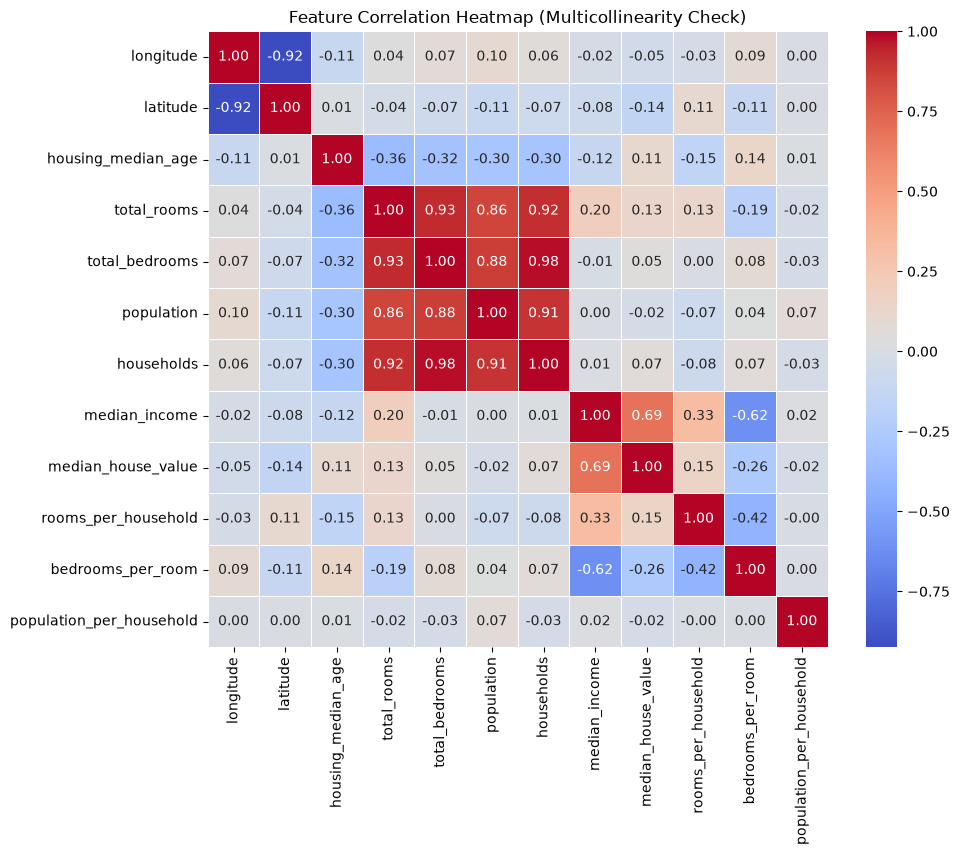

In [4]:
plt.figure(figsize=(10, 8))
correlation_matrix = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(
    correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Feature Correlation Heatmap (Multicollinearity Check)")
plt.show()

### 2. Exploratory Data Analysis & Statistical Summary
* **Dataset Schema & Types**: Used `.info()` to confirm 20,640 total entries across 10 features—9 numerical (`float64`) and 1 categorical (`ocean_proximity`).
* **Missing Value Audit**: Used `.isnull().sum()` to isolate missing values specifically inside `total_bedrooms` (20,433 non-null entries, leaving 207 missing records to impute).
* **Statistical Distribution**: Executed `.describe()` to inspect feature scales, quartiles, and confirm the $500,001 upper cap on `median_house_value`.

In [5]:
print("BASIC INSIGHTS OF DATASET:-\n")
print("Information of Dataset\n")
print(df.info())
print("\n")
print("Missing Values:-\n")
print(df.isnull().sum())
print("\n")
print("Statistical Insights:-\n")
print(df.describe())

BASIC INSIGHTS OF DATASET:-

Information of Dataset

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20433 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  str    
 10  rooms_per_household       20640 non-null  float64
 11  bedrooms_per_room         20433 non-null  float64
 12  population_per_household  20640 non-null  float64
dtypes: float64(12), str

### 3. Feature-Target Separation & Train-Test Split
* **Feature Matrix & Target Vector**: Separated `median_house_value` as the target variable (`y`) and retained the remaining 9 predictors in `X`.
* **Data Partitioning**: Split the dataset into 80% training and 20% testing subsets (`random_state=42`) before applying any transformations to prevent data leakage.

In [6]:
X=df.drop(columns=["median_house_value"])
y=df["median_house_value"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

### 4. Leak-Free Preprocessing & Feature Engineering Pipeline
* **Numerical Pipeline**: Built a sequential `Pipeline` using median `SimpleImputer` for `total_bedrooms`, `PolynomialFeatures(degree=2)` to capture non-linear feature interactions, and `StandardScaler` for normalization.
* **Categorical Pipeline**: Configured `OneHotEncoder(handle_unknown="ignore")` to convert `ocean_proximity` into binary indicator columns.
* **ColumnTransformer Integration**: Combined both branches via `ColumnTransformer`, fitting strictly on `X_train` and transforming `X_test`.

In [7]:
#1.Defining the numerical and categorical columns
numerical_cols=["longitude","latitude","housing_median_age","total_rooms","total_bedrooms","population","households","median_income","rooms_per_household","bedrooms_per_room","population_per_household"]
categorical_cols=["ocean_proximity"]

#2.Pipeline for Numerical Data:First Impute (median), then Standardize
numeric_transformer= Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("scaler", StandardScaler()),])

#3.Pipeline for Categorical Data: Impute missing (most frequent) then OHE
categorical_transformer = Pipeline(
    steps=[
        ("onehot",OneHotEncoder(handle_unknown="ignore", sparse_output=False)),])

#4.Combine both using ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_cols),
        ("cat", categorical_transformer, categorical_cols),
    ])

In [8]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

### 5. Model Training, Hyperparameter Tuning & Evaluation
* **Model Initialization & Grid Search**: Instantiated OLS, Ridge, and Lasso estimators, configuring comprehensive hyperparameter grids (`alpha`, `fit_intercept`, `solver`, `selection`) paired with `GridSearchCV` (5-fold cross-validation via negative MSE scoring)[cite: 4].
* **Execution & Extraction**: Fitted models securely on preprocessed training partitions, extracted optimal hyperparameters, and generated predictions on the test set.
* **Performance Benchmarking**: Evaluated all three models using standard regression metrics ($\text{RMSE}$, $\text{MAE}$, and $R^2$ score) to compare linear baseline performance[cite: 4].

#### Why is accuracy capped around ~67% ($R^2 \approx 0.67$)?
1. **The $500,001 Target Price Ceiling:** In the original 1990 California census data, every luxury home valued above $500k was artificially chopped off and flatly capped at **$500,001**. Because thousands of high-income coastal properties share this exact flat limit, linear equations cannot properly reconcile why homes with massive income and prime geographic markers are restricted to a single flat value, creating a strict performance ceiling.
2. **Inherent Non-Linearity:** Housing markets do not scale in straight lines. Spatial coordinates (longitude and latitude) interact with population density and median income in complex, non-linear geographic clusters that linear hyperplanes cannot fully capture.

In [ ]:
#1.Initialize the models
ridge = Ridge()
lasso = Lasso(max_iter=1000) 
ols = LinearRegression()
# 2.Make parameters grids:-

ridge_param_grid = {
    'alpha': [0.01, 0.1, 1.0, 10.0, 50.0, 100.0, 200.0, 500.0],
    'fit_intercept': [True, False],
    'solver': ['auto', 'svd', 'cholesky', 'lsqr']}

lasso_param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    'fit_intercept': [True, False],
    'max_iter': [10000],  # Keeps it high so Lasso doesn't throw convergence warnings
    'selection': ['cyclic', 'random']}

# 3. Setup GridSearchCV using 5-fold cross-validation and Negative Mean Squared Error as scoring

ridge_grid = GridSearchCV(
    estimator=Ridge(),
    param_grid=ridge_param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1)

lasso_grid = GridSearchCV(
    estimator=Lasso(),
    param_grid=lasso_param_grid,
    scoring='neg_mean_squared_error',
    cv=5,
    n_jobs=-1)

# 4. Fit the GridSearch CV objects on the preprocessed training data

ols.fit(X_train_processed, y_train)
ridge_grid.fit(X_train_processed, y_train)
lasso_grid.fit(X_train_processed, y_train)

# 5. Extract the best estimators
best_ridge = ridge_grid.best_estimator_
best_lasso = lasso_grid.best_estimator_

print('Best Ridge Alpha:', ridge_grid.best_params_)
print('Best Lasso Alpha:', lasso_grid.best_params_)

# 6. Make predictions on the test set
y_pred_ols = ols.predict(X_test_processed)
y_pred_ridge = best_ridge.predict(X_test_processed)
y_pred_lasso = best_lasso.predict(X_test_processed)


# 7. Evaluation function for RMSE, MAE, and R2
def evaluate_model(y_true, y_pred, model_name):
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mae = mean_absolute_error(y_true, y_pred)
  r2 = r2_score(y_true, y_pred)

  print(f'--- {model_name} Performance ---')
  print(f'RMSE: {rmse:.4f}')
  print(f'MAE:  {mae:.4f}')
  print(f'R2:   {r2:.4f}\n')


evaluate_model(y_test, y_pred_ridge, 'Ridge Regression')
evaluate_model(y_test, y_pred_lasso, 'Lasso Regression')
evaluate_model(y_test, y_pred_ols, "Ordinary Least Squares (OLS)")

### 6. Residual Distribution Curves & Error Analysis
* **Residual Calculation**: Computed prediction errors ($\text{Residual} = y_{\text{test}} - y_{\text{pred}}$) for OLS, Ridge, and Lasso models to evaluate error dispersion.
* **Interactive Visualization**: Leveraged Plotly's `figure_factory.create_distplot` to generate smooth, overlapping kernel density estimation (KDE) curves with a bin size of 2,000, suppressing histograms for clean comparative clarity[cite: 4].

#### Visual Analysis of the Residual Curves
1. **Zero-Centered Error Spread:** All three models (OLS, Ridge, and Lasso) show heavily overlapping curves centered tightly around zero, indicating that the predictions are unbiased on average.
2. **Error Tails & Skewness:** The symmetrical bell-like peaks stretch out significantly toward the positive and negative directions (ranging past $-200\text{k}$ to $+200\text{k}$ and beyond). This broad dispersion reflects the high variance and prediction errors caused by the $500,001 data cap and non-linear housing features.
3. **Model Parity:** The nearly identical shape and overlap of the OLS, Ridge, and Lasso curves prove that regularizing with L1 (Lasso) and L2 (Ridge) penalties yielded virtually the same error distribution as unregularized OLS.

In [ ]:
import plotly.figure_factory as fig_ff
import numpy as np

# Calculate residuals (errors)
residuals_ols = y_test - y_pred_ols
residuals_ridge = y_test - y_pred_ridge
residuals_lasso = y_test - y_pred_lasso

# Plot residual distributions interactively
fig = fig_ff.create_distplot(
    [list(residuals_ols),
    list(residuals_ridge),
    list(residuals_lasso)],
    ["OLS Residuals", "Ridge Residuals", "Lasso Residuals"],
    bin_size=2000,
    show_hist=False)

fig.update_layout(
    title="Residual Distribution Curves Comparison",
    xaxis_title="Residual Error (Actual - Predicted)",
    yaxis_title="Density",
    width=800,
    height=500)

fig.show()

### 7. Actual vs. Predicted Scatter Analysis & Data Cap Visualization
* **Interactive Multi-Multi Scatter:** Built a multi-trace Plotly figure (`go.Figure`) to plot true test values (x-axis) against predicted housing prices (y-axis) for OLS (blue), Ridge (orange), and Lasso (pink).
* **Ideal Prediction Reference:** Added a dashed red y = x diagonal reference line representing perfect predictions where actual values equal predicted values.

#### Visual Insights & The $500,001 Price Wall

* **The Vertical Capping Artifact:** The plot clearly exposes a distinct vertical wall of data points clustered right at the 500,001 mark on the x-axis. Because the original 1990 census data forcefully capped luxury home prices at this exact threshold, models receive mixed feature signals (such as high median income and prime coastal locations) that cause them to predict values ranging anywhere from 200k up to nearly 800k for homes flatly restricted at the ceiling.
* **Model Parity:** The heavily overlapping marker points visually reinforce that OLS, Ridge, and Lasso learned nearly identical linear coefficients and error structures.

In [ ]:
import plotly.graph_objects as go

#Create a scatter plot comparing Actual vs. Predicted for OLS, Ridge, and Lasso
fig = go.Figure()

#1.Add scatter points for OLS
fig.add_trace(go.Scatter(
        x=y_test,
        y=y_pred_ols,
        mode="markers",
        marker=dict(color="blue", opacity=0.5, size=6),
        name="OLS Predictions"))

# 2. Add scatter points for Ridge and Lasso
fig.add_trace(go.Scatter(
        x=y_test,
        y=y_pred_ridge,
        mode="markers",
        marker=dict(color="orange", opacity=0.5, size=6),
        name="Ridge Predictions"))

fig.add_trace(go.Scatter(
        x=y_test,
        y=y_pred_lasso,
        mode="markers",
        marker=dict(color="pink", opacity=0.5, size=6),
        name="Lasso Predictions"))


# 3. Add the ideal "Perfect Prediction" reference line (y = x)
min_val = min(y_test.min(), y_pred_ols.min())
max_val = max(y_test.max(), y_pred_ols.max())

fig.add_trace(
    go.Scatter(
        x=[min_val, max_val],
        y=[min_val, max_val],
        mode="lines",
        line=dict(color="red", dash="dash", width=2),
        name="Ideal Prediction (y = x)"))

# Layout adjustments
fig.update_layout(
    title="Actual vs Predicted Housing Prices (Linear Models)",
    xaxis_title="Actual Median House Value",
    yaxis_title="Predicted Median House Value",
    width=800,
    height=600)

fig.show()